# Flood model: next-day training, calibration, and evaluation

Use `merge_dataset/all_clean_data_merged.csv` as the single modeling source. The target is the **observed satellite flood label on the next calendar day** for the same district. GFS forecast fields issued on the feature date and static terrain are predictors. Steps run in order: load/QA ? label audit ? next-day target and temporal split ? validation model selection ? calibration ? untouched 2026 test ? next-day scenario.

Important: blank `flood_obs` means no verified label, not no flood. The new label file and the previous flood-history file disagree on some overlapping dates; `flood_obs` in the merged file is the new label source and `flood_obs_legacy` is retained only for comparison. Probabilities are calibrated to these satellite-observed labels, not guaranteed real-world flood risk. Verify GFS forecast-window metadata before operational use.

In [23]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, f1_score, fbeta_score, log_loss,
    precision_score, recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "Leelawadee UI"

DATA_FILE = "all_clean_data_merged.csv"
TARGET = "flood_obs"
RANDOM_STATE = 42
EMBARGO_DAYS = 3
project_root = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / "merge_dataset" / DATA_FILE).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(f"Cannot find merge_dataset/{DATA_FILE} from {Path.cwd()}")
DATA_PATH = project_root / "merge_dataset" / DATA_FILE
SPLIT_DIR = project_root / "Model" / "modeltest_splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Training source: {DATA_PATH}")

Training source: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\merge_dataset\all_clean_data_merged.csv


## 1. Load and validate the merged dataset

Keep amphoe rows for prediction; province-level rows are useful in the master file but are not model examples. Verify unique date/district keys, label availability, GFS coverage, and the date range before modeling.

Merged shape: 47,516 rows x 192 columns
Amphoe rows: 45,324; districts: 18
Date range: 2020-01-01 to 2026-11-22
Amphoe flood labels (NaN is unobserved, not no-flood):


,rows
flood_obs,
NaN,38851
1.0,5805
0.0,668


Label coverage and class balance by year:


,rows,labeled,flood,no_flood,label_coverage_pct,flood_pct_of_labels
year,,,,,,
2020,6588,777,710.0,67.0,11.79,91.38
2021,6570,790,712.0,78.0,12.02,90.13
2022,6570,1052,960.0,92.0,16.01,91.25
2023,6570,1025,914.0,111.0,15.60,89.17
2024,6588,981,851.0,130.0,14.89,86.75
2025,6570,959,855.0,104.0,14.60,89.16
2026,5868,889,803.0,86.0,15.15,90.33


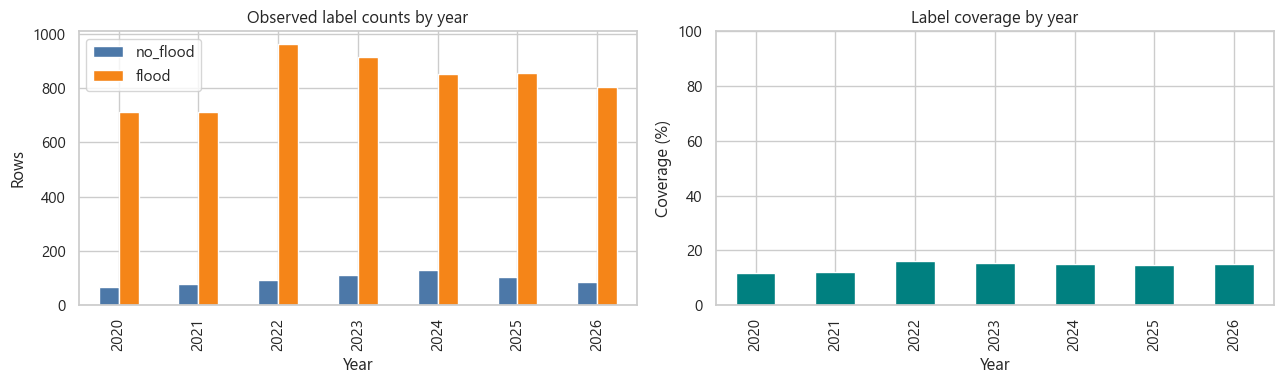

In [24]:
data_all = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    parse_dates=["date"],
    low_memory=False,
)
required_columns = {
    "date", "unit_level", "district_code", "district", TARGET,
    "label_available", "gfs_available", "gfs_issue_time", "gfs_valid_time",
    "rain_next_24h_mm", "rain_next_48h_mm", "rain_next_72h_mm",
    "up_rain_next_24h_mm", "up_rain_next_48h_mm", "up_rain_next_72h_mm",
}
missing_columns = sorted(required_columns - set(data_all.columns))
if missing_columns:
    raise ValueError(f"Merged dataset is missing required columns: {missing_columns}")
if data_all["date"].isna().any():
    raise ValueError("Invalid dates found in the merged dataset.")
if data_all.duplicated(["date", "unit_level", "district_code"]).any():
    raise ValueError("Duplicate date/unit/district keys found in the merged dataset.")

amphoe_data = data_all.loc[data_all["unit_level"].eq("amphoe")].copy()
if not amphoe_data[TARGET].dropna().isin([0, 1]).all():
    raise ValueError("flood_obs must contain only 0, 1, or missing values.")
if not amphoe_data["label_available"].eq(amphoe_data[TARGET].notna().astype("int8")).all():
    raise ValueError("label_available does not agree with flood_obs.")

print(f"Merged shape: {data_all.shape[0]:,} rows x {data_all.shape[1]} columns")
print(f"Amphoe rows: {len(amphoe_data):,}; districts: {amphoe_data['district_code'].nunique()}")
print(f"Date range: {amphoe_data['date'].min().date()} to {amphoe_data['date'].max().date()}")
print("Amphoe flood labels (NaN is unobserved, not no-flood):")
display(amphoe_data[TARGET].value_counts(dropna=False).rename("rows").to_frame())

by_year = amphoe_data.assign(year=amphoe_data["date"].dt.year).groupby("year").agg(
    rows=(TARGET, "size"),
    labeled=(TARGET, "count"),
    flood=(TARGET, "sum"),
)
by_year["no_flood"] = by_year["labeled"] - by_year["flood"]
by_year["label_coverage_pct"] = 100 * by_year["labeled"] / by_year["rows"]
by_year["flood_pct_of_labels"] = 100 * by_year["flood"] / by_year["labeled"]
print("Label coverage and class balance by year:")
display(by_year.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_year[["no_flood", "flood"]].plot(kind="bar", ax=axes[0], color=["#4C78A8", "#F58518"])
axes[0].set(title="Observed label counts by year", xlabel="Year", ylabel="Rows")
by_year["label_coverage_pct"].plot(kind="bar", ax=axes[1], color="teal")
axes[1].set(title="Label coverage by year", xlabel="Year", ylabel="Coverage (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()

## 2. Audit label provenance and input readiness

Use the merged file's new `flood_obs` as the target and keep `flood_obs_legacy` out of predictors. Report disagreements rather than blending conflicting labels. GFS must be available on the feature date; scene-observation fields are not predictors because they can arrive after the forecast issue time.

In [25]:
labeled = amphoe_data.loc[amphoe_data[TARGET].isin([0, 1])].copy()
label_summary = pd.DataFrame({
    "rows": [int(labeled[TARGET].eq(0).sum()), int(labeled[TARGET].eq(1).sum())],
    "percent": [100 * labeled[TARGET].eq(0).mean(), 100 * labeled[TARGET].eq(1).mean()],
}, index=["No flood (0)", "Flood (1)"])
display(label_summary.round(2))

legacy_overlap = amphoe_data.loc[
    amphoe_data[TARGET].notna() & amphoe_data["flood_obs_legacy"].notna()
]
disagreements = int(legacy_overlap[TARGET].ne(legacy_overlap["flood_obs_legacy"]).sum())
print(
    f"New/legacy labels overlap: {len(legacy_overlap):,}; "
    f"disagreements: {disagreements:,}. Only new flood_obs is used as target."
)
print(
    f"Labeled rows with valid_frac < 0.8: "
    f"{int(labeled['valid_frac'].lt(0.8).sum()):,}"
)
print(
    f"Rows without labels: {int(amphoe_data[TARGET].isna().sum()):,}; "
    f"these are excluded as targets, never recoded as 0."
)

input_readiness = pd.DataFrame({
    "nonmissing_rows": amphoe_data[[
        "gfs_available", "rain_next_24h_mm", "rain_next_48h_mm", "rain_next_72h_mm",
        "up_rain_next_24h_mm", "up_rain_next_48h_mm", "up_rain_next_72h_mm",
        "temperature_2m", "relative_humidity_2m", "wind_u_10m", "wind_v_10m",
    ]].notna().sum(),
})
print("GFS predictor coverage:")
display(input_readiness)

,rows,percent
No flood (0),668,10.32
Flood (1),5805,89.68


New/legacy labels overlap: 5,584; disagreements: 569. Only new flood_obs is used as target.
Labeled rows with valid_frac < 0.8: 0
Rows without labels: 38,851; these are excluded as targets, never recoded as 0.
GFS predictor coverage:


,nonmissing_rows
gfs_available,45324
rain_next_24h_mm,42789
rain_next_48h_mm,42738
rain_next_72h_mm,42738
up_rain_next_24h_mm,45306
up_rain_next_48h_mm,45252
up_rain_next_72h_mm,45252
temperature_2m,42721
relative_humidity_2m,42721
wind_u_10m,42721


## 3. Build the next-calendar-day target and chronological splits

For each district, shift the observed label from date `t+1` onto the predictor row dated `t`. Use only consecutive calendar days, observed next-day labels, and available GFS inputs. A three-day embargo separates temporal splits. Model selection uses 2023 Validation; calibration uses 2024?2025; the newest 2026 labels are held out for Test.

In [26]:
data = amphoe_data.sort_values(["district_code", "date"]).copy()
data["gfs_issue_time"] = pd.to_datetime(data["gfs_issue_time"], errors="coerce", utc=True)
data["gfs_valid_time"] = pd.to_datetime(data["gfs_valid_time"], errors="coerce", utc=True)
gfs_rows = data.loc[data["gfs_available"].eq(1)]
if gfs_rows["gfs_issue_time"].isna().any():
    raise ValueError("Rows marked GFS-available are missing issue timestamps.")
issue_date = gfs_rows["gfs_issue_time"].dt.tz_convert(None).dt.normalize()
if issue_date.gt(gfs_rows["date"]).any():
    raise ValueError("GFS issue time occurs after the predictor date; this would leak future inputs.")

by_district = data.groupby("district_code", sort=False)
data["target_date"] = by_district["date"].shift(-1)
next_label = by_district[TARGET].shift(-1)
next_label_available = by_district["label_available"].shift(-1).eq(1)
is_next_day = data["target_date"].sub(data["date"]).dt.days.eq(1)
data["flood_next_day"] = next_label.where(is_next_day & next_label_available)

static_columns = [
    "elevation_m", "slope_deg", "tpi_2km_m", "bowl_frac", "hand_m",
    "frac_hand_lt5", "frac_hand_lt10", "twi", "clay_pct", "sand_pct",
    "lc_tree", "lc_crop", "impervious_built_frac", "lc_water", "lc_wetland",
    "lc_mangrove", "river_km_per_km2", "river_max_cms",
]
categorical_features = ["district"]
numeric_features = [
    "rain_next_24h_mm", "rain_next_48h_mm", "rain_next_72h_mm",
    "up_rain_next_24h_mm", "up_rain_next_48h_mm", "up_rain_next_72h_mm",
    "temperature_2m", "relative_humidity_2m", "wind_u_10m", "wind_v_10m",
    "month_sin", "month_cos", "doy_sin", "doy_cos", *static_columns,
]
FEATURE_COLUMNS = [*categorical_features, *numeric_features]

eligible = data.loc[
    data["flood_next_day"].notna() & data["gfs_available"].eq(1)
].copy()
eligible["flood_next_day"] = eligible["flood_next_day"].astype("int8")
if eligible.empty:
    raise ValueError("No next-day observed labels have usable GFS inputs.")
doy = eligible["date"].dt.dayofyear
eligible["month_sin"] = np.sin(2 * np.pi * eligible["date"].dt.month / 12)
eligible["month_cos"] = np.cos(2 * np.pi * eligible["date"].dt.month / 12)
eligible["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
eligible["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
all_missing_features = eligible[FEATURE_COLUMNS].columns[eligible[FEATURE_COLUMNS].isna().all()].tolist()
if all_missing_features:
    raise ValueError(f"All values are missing for features: {all_missing_features}")

train = eligible.loc[eligible["target_date"].le("2022-12-27")].copy()
validation = eligible.loc[eligible["target_date"].between("2023-01-04", "2023-12-27")].copy()
calibration = eligible.loc[eligible["target_date"].between("2024-01-04", "2025-12-28")].copy()
test = eligible.loc[eligible["target_date"].between("2026-01-04", "2026-11-22")].copy()
splits = {"Train": train, "Validation": validation, "Calibration": calibration, "Test 2026": test}
for split_name, split in splits.items():
    if split.empty or split["flood_next_day"].nunique() != 2:
        raise ValueError(f"{split_name} must contain both classes; got {len(split):,} rows.")

split_summary = pd.DataFrame([
    {
        "rows": len(frame),
        "no_flood": int(frame["flood_next_day"].eq(0).sum()),
        "flood": int(frame["flood_next_day"].eq(1).sum()),
        "flood_rate": frame["flood_next_day"].mean(),
        "target_start": frame["target_date"].min(),
        "target_end": frame["target_date"].max(),
    }
    for frame in splits.values()
], index=splits.keys())
print(f"Eligible one-day-ahead examples: {len(eligible):,}")
print(f"Rows excluded by the temporal embargo: {len(eligible) - sum(map(len, splits.values())):,}")
display(split_summary.round({"flood_rate": 4}))
print(f"Predictors: {len(FEATURE_COLUMNS)} total ({len(numeric_features)} numeric, {len(categorical_features)} categorical)")
print("GFS `forecast_hours`/`gfs_valid_time` are recorded at 72h; verify how the rain_next_* windows were exported before operational use.")

Eligible one-day-ahead examples: 6,456
Rows excluded by the temporal embargo: 55


,rows,no_flood,flood,flood_rate,target_start,target_end
Train,2602,235,2367,0.9097,2020-01-06,2022-12-27
Validation,1025,111,914,0.8917,2023-01-07,2023-12-22
Calibration,1902,231,1671,0.8785,2024-01-14,2025-12-23
Test 2026,872,85,787,0.9025,2026-01-04,2026-11-19


Predictors: 33 total (32 numeric, 1 categorical)
GFS `forecast_hours`/`gfs_valid_time` are recorded at 72h; verify how the rain_next_* windows were exported before operational use.


## 4. Select a model, calibrate, and evaluate on the 2026 holdout

Choose among Logistic Regression, Random Forest, and XGBoost on Validation only. Refit the selected model on Train+Validation, fit a sigmoid calibrator on the separate 2024?2025 Calibration set, and evaluate once on the 2026 Test set. Compare probability scores with the raw model and a prevalence baseline; report class imbalance alongside accuracy.

In [27]:
def make_model(model_name):
    numeric_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    if model_name == "Logistic Regression":
        numeric_steps.append(("scaler", StandardScaler()))
    preprocessor = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric_features),
        ("category", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])
    if model_name == "Logistic Regression":
        estimator = LogisticRegression(class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE)
    elif model_name == "Random Forest":
        estimator = RandomForestClassifier(
            n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
            max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1,
        )
    elif model_name == "XGBoost":
        estimator = XGBClassifier(
            n_estimators=250, max_depth=2, learning_rate=0.03,
            subsample=0.9, colsample_bytree=0.8, min_child_weight=1,
            reg_lambda=2, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1,
        )
    else:
        raise ValueError(f"Unsupported model: {model_name}")
    return Pipeline([("preprocess", preprocessor), ("model", estimator)])


def probability_metrics(y_true, probability, threshold=0.5):
    predicted = (probability >= threshold).astype("int8")
    return {
        "accuracy": accuracy_score(y_true, predicted),
        "balanced_accuracy": balanced_accuracy_score(y_true, predicted),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "f1": f1_score(y_true, predicted, zero_division=0),
        "f2": fbeta_score(y_true, predicted, beta=2, zero_division=0),
        "pr_auc": average_precision_score(y_true, probability),
        "brier_score": brier_score_loss(y_true, probability),
        "log_loss": log_loss(y_true, probability, labels=[0, 1]),
    }

X_train, y_train = train[FEATURE_COLUMNS], train["flood_next_day"].astype(int)
X_val, y_val = validation[FEATURE_COLUMNS], validation["flood_next_day"].astype(int)
validation_rows = []
for model_name in ["Logistic Regression", "Random Forest", "XGBoost"]:
    candidate = make_model(model_name)
    candidate.fit(X_train, y_train)
    probability = candidate.predict_proba(X_val)[:, 1]
    validation_rows.append({"model": model_name, **probability_metrics(y_val, probability)})
validation_results = pd.DataFrame(validation_rows).set_index("model").sort_values(
    ["pr_auc", "balanced_accuracy", "recall"], ascending=False
)
selected_model_name = validation_results.index[0]
display(validation_results.round(4))
print(f"Selected model by Validation PR-AUC: {selected_model_name}")

# Refit only through 2023; later periods remain separate for calibration and testing.
development = pd.concat([train, validation]).sort_values(["target_date", "district_code"])
deployment_model = make_model(selected_model_name)
deployment_model.fit(development[FEATURE_COLUMNS], development["flood_next_day"].astype(int))
y_calibration = calibration["flood_next_day"].astype(int)
calibrated_model = CalibratedClassifierCV(
    estimator=FrozenEstimator(deployment_model), method="sigmoid"
)
calibrated_model.fit(calibration[FEATURE_COLUMNS], y_calibration)

X_test, y_test = test[FEATURE_COLUMNS], test["flood_next_day"].astype(int)
raw_test_probability = deployment_model.predict_proba(X_test)[:, 1]
test_probability = calibrated_model.predict_proba(X_test)[:, 1]
test_metrics = pd.DataFrame([
    probability_metrics(y_test, raw_test_probability),
    probability_metrics(y_test, test_probability),
], index=["Raw model", "Sigmoid calibrated"])
train_prevalence = float(development["flood_next_day"].mean())
baseline_probability = np.full(len(y_test), train_prevalence)
baseline_brier = brier_score_loss(y_test, baseline_probability)
baseline_log_loss = log_loss(y_test, baseline_probability, labels=[0, 1])
majority_accuracy = accuracy_score(y_test, np.ones(len(y_test), dtype="int8"))
print("Held-out 2026 Test metrics:")
display(test_metrics.round(4))
print(
    f"Train+Validation flood prevalence={train_prevalence:.4f}; "
    f"baseline Brier={baseline_brier:.4f}; baseline Log-loss={baseline_log_loss:.4f}; "
    f"always-flood accuracy={majority_accuracy:.4f}"
)
print("Calibrated confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, (test_probability >= 0.5).astype("int8"), labels=[0, 1]))

metrics_path = SPLIT_DIR / "gfs_nextday_test_2026_metrics.csv"
validation_results.to_csv(SPLIT_DIR / "gfs_nextday_validation_metrics.csv", encoding="utf-8-sig")
test_metrics.to_csv(metrics_path, encoding="utf-8-sig")
model_path = SPLIT_DIR / "flood_next_day_gfs_sigmoid_calibrated_model.joblib"
joblib.dump({
    "model": calibrated_model,
    "feature_columns": FEATURE_COLUMNS,
    "target": "flood_next_day",
    "source": str(DATA_PATH),
    "base_training_period": "2020-01-01..2023-12-27 target dates",
    "calibration_period": "2024-01-04..2025-12-28 target dates",
    "test_period": "2026-01-04..2026-11-22 target dates",
    "forecast_horizon_days": 1,
    "warning": "Calibrated to satellite-observed labels, not verified real-world flood prevalence.",
}, model_path)
print(f"Saved Test metrics: {metrics_path}")
print(f"Saved calibrated model: {model_path}")

,accuracy,balanced_accuracy,precision,recall,f1,f2,pr_auc,brier_score,log_loss
model,,,,,,,,,
Logistic Regression,0.8839,0.9309,0.9987,0.8709,0.9305,0.8938,0.9947,0.0820,0.2460
XGBoost,0.9180,0.6968,0.9323,0.9792,0.9552,0.9695,0.9943,0.0528,0.1562
Random Forest,0.9151,0.8060,0.9589,0.9453,0.9521,0.9480,0.9935,0.0546,0.1947


Selected model by Validation PR-AUC: Logistic Regression
Held-out 2026 Test metrics:


,accuracy,balanced_accuracy,precision,recall,f1,f2,pr_auc,brier_score,log_loss
Raw model,0.8739,0.9039,0.9927,0.8666,0.9254,0.8892,0.994,0.0907,0.2726
Sigmoid calibrated,0.9232,0.7528,0.9511,0.9644,0.9577,0.9617,0.994,0.0534,0.1652


Train+Validation flood prevalence=0.9046; baseline Brier=0.0880; baseline Log-loss=0.3195; always-flood accuracy=0.9025
Calibrated confusion matrix [[TN, FP], [FN, TP]]:
[[ 46  39]
 [ 28 759]]
Saved Test metrics: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\Model\modeltest_splits\gfs_nextday_test_2026_metrics.csv
Saved calibrated model: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\Model\modeltest_splits\flood_next_day_gfs_sigmoid_calibrated_model.joblib


## 5. กราฟผลทดสอบปี 2026 (Test)

กราฟชุดนี้ช่วยดูทั้งคำตอบแบบท่วม/ไม่ท่วมและความน่าเชื่อถือของเปอร์เซ็นต์ความเสี่ยง: **Confusion Matrix** แสดงจำนวนทายถูก/ผิดที่ threshold 50%, **กราฟ Calibration** เปรียบเทียบโอกาสที่โมเดลให้กับสัดส่วนที่เกิดจริง และ **กราฟรายวัน** เปรียบเทียบอัตราท่วมจริงกับความเสี่ยงเฉลี่ยของอำเภอที่มี label ในวันนั้น

ข้อควรระวัง: Accuracy อาจดูสูงเพราะข้อมูล Test มีเหตุการณ์ท่วมประมาณ 90%; อ่านจำนวน False Alarm และ Missed Flood ใน Confusion Matrix ประกอบด้วย

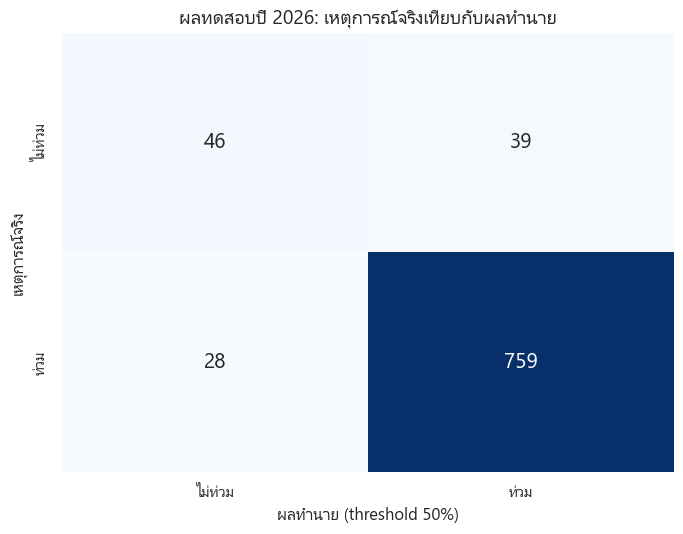

ทายถูกว่าไม่ท่วม 46 | แจ้งท่วมเกินจริง 39 | พลาดเหตุท่วม 28 | ทายถูกว่าท่วม 759
Accuracy=92.3%; Balanced Accuracy=75.3%. ควรดูสองค่านี้และจำนวนผิดพลาดคู่กัน เพราะข้อมูลท่วม/ไม่ท่วมไม่สมดุล


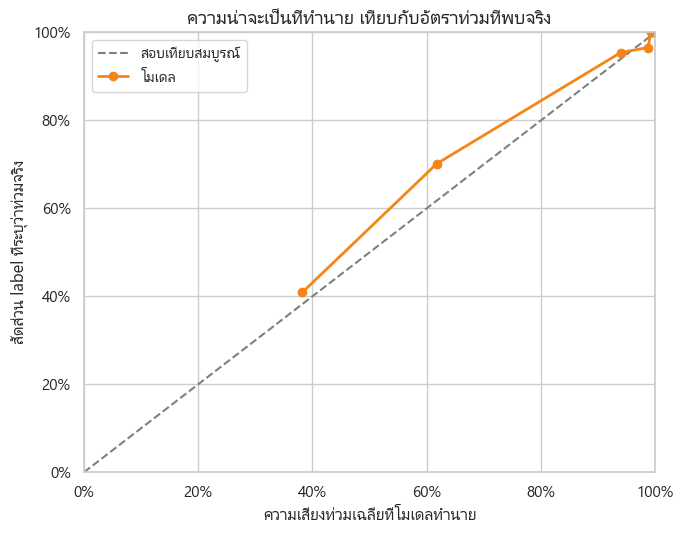

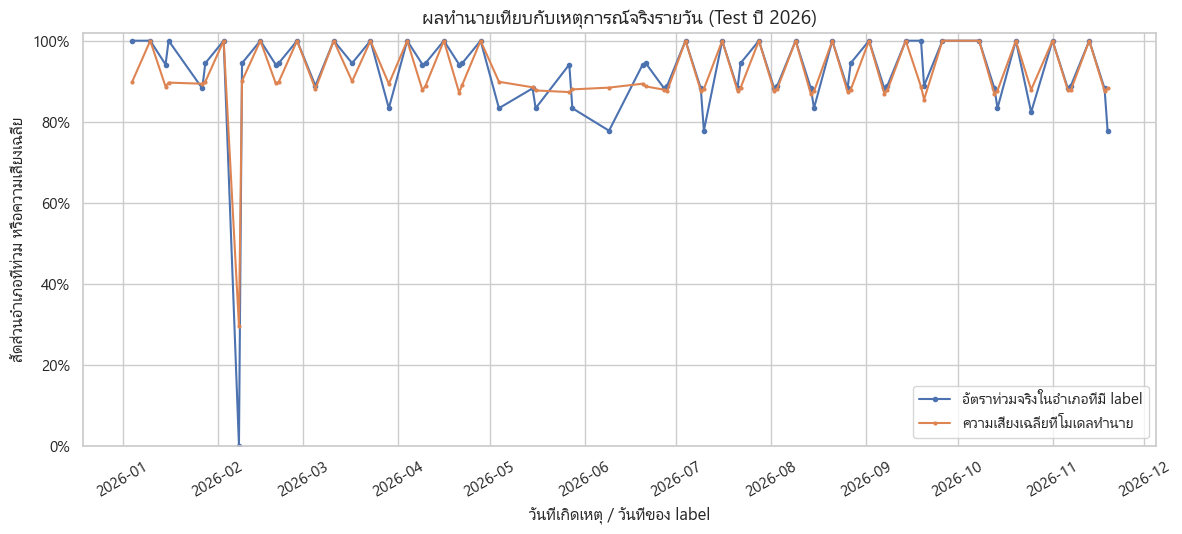

บันทึกกราฟ Confusion Matrix: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\Model\modeltest_splits\gfs_nextday_test_2026_confusion_matrix_th.png
บันทึกกราฟ Calibration: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\Model\modeltest_splits\gfs_nextday_test_2026_calibration_th.png
บันทึกกราฟรายวัน: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\Model\modeltest_splits\gfs_nextday_test_2026_daily_match_th.png


In [28]:
from sklearn.calibration import calibration_curve
from matplotlib.ticker import PercentFormatter

# 1) จำนวนผลทำนายถูกและผิด เมื่อใช้ threshold 50%
test_predictions = (test_probability >= 0.5).astype("int8")
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["ไม่ท่วม", "ท่วม"],
    yticklabels=["ไม่ท่วม", "ท่วม"],
    annot_kws={"size": 15}, ax=ax,
)
ax.set_title("ผลทดสอบปี 2026: เหตุการณ์จริงเทียบกับผลทำนาย", fontsize=14)
ax.set_xlabel("ผลทำนาย (threshold 50%)")
ax.set_ylabel("เหตุการณ์จริง")
plt.tight_layout()
confusion_plot_path = SPLIT_DIR / "gfs_nextday_test_2026_confusion_matrix_th.png"
fig.savefig(confusion_plot_path, dpi=160, bbox_inches="tight")
plt.show()

true_negative, false_positive, false_negative, true_positive = cm.ravel()
print(
    f"ทายถูกว่าไม่ท่วม {true_negative:,} | แจ้งท่วมเกินจริง {false_positive:,} | "
    f"พลาดเหตุท่วม {false_negative:,} | ทายถูกว่าท่วม {true_positive:,}"
)
print(
    f"Accuracy={accuracy_score(y_test, test_predictions):.1%}; "
    f"Balanced Accuracy={balanced_accuracy_score(y_test, test_predictions):.1%}. "
    "ควรดูสองค่านี้และจำนวนผิดพลาดคู่กัน เพราะข้อมูลท่วม/ไม่ท่วมไม่สมดุล"
)

# 2) ยิ่งจุดอยู่ใกล้เส้นประมาก ความน่าจะเป็นยิ่งสอดคล้องกับอัตราที่พบจริง
observed_rate, predicted_rate = calibration_curve(
    y_test, test_probability, n_bins=10, strategy="quantile"
)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="สอบเทียบสมบูรณ์")
ax.plot(predicted_rate, observed_rate, marker="o", linewidth=2, color="#F58518", label="โมเดล")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("ความน่าจะเป็นที่ทำนาย เทียบกับอัตราท่วมที่พบจริง", fontsize=14)
ax.set_xlabel("ความเสี่ยงท่วมเฉลี่ยที่โมเดลทำนาย")
ax.set_ylabel("สัดส่วน label ที่ระบุว่าท่วมจริง")
ax.legend()
plt.tight_layout()
calibration_plot_path = SPLIT_DIR / "gfs_nextday_test_2026_calibration_th.png"
fig.savefig(calibration_plot_path, dpi=160, bbox_inches="tight")
plt.show()

# 3) เปรียบเทียบแนวโน้มรายวัน เฉพาะอำเภอที่มี label ใน Test
plot_rows = test[["target_date", "district_code", "flood_next_day"]].copy()
plot_rows["probability"] = test_probability
daily_test = plot_rows.groupby("target_date").agg(
    observed_flood_rate=("flood_next_day", "mean"),
    predicted_flood_rate=("probability", "mean"),
    labeled_districts=("district_code", "nunique"),
).sort_index()
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(daily_test.index, daily_test["observed_flood_rate"], marker="o", markersize=3,
        linewidth=1.5, label="อัตราท่วมจริงในอำเภอที่มี label")
ax.plot(daily_test.index, daily_test["predicted_flood_rate"], marker=".", markersize=4,
        linewidth=1.5, label="ความเสี่ยงเฉลี่ยที่โมเดลทำนาย")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1.02)
ax.set_title("ผลทำนายเทียบกับเหตุการณ์จริงรายวัน (Test ปี 2026)", fontsize=14)
ax.set_xlabel("วันที่เกิดเหตุ / วันที่ของ label")
ax.set_ylabel("สัดส่วนอำเภอที่ท่วม หรือความเสี่ยงเฉลี่ย")
ax.legend(loc="best")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
daily_plot_path = SPLIT_DIR / "gfs_nextday_test_2026_daily_match_th.png"
fig.savefig(daily_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"บันทึกกราฟ Confusion Matrix: {confusion_plot_path}")
print(f"บันทึกกราฟ Calibration: {calibration_plot_path}")
print(f"บันทึกกราฟรายวัน: {daily_plot_path}")

## 5. Produce a next-day district scenario

Use the most recent date in the merged file as the forecast issue/input date. Require current GFS inputs for all 18 districts. This is still only a scenario from archived satellite labels and the GFS extract; report the input timestamp and forecast metadata in the output.

In [29]:
latest_input_date = data["date"].max()
forecast_date = latest_input_date + pd.Timedelta(days=1)
forecast_rows = data.loc[data["date"].eq(latest_input_date)].copy()
if forecast_rows["district_code"].nunique() != 18:
    raise ValueError("The latest date does not contain all 18 amphoe districts.")
if forecast_rows["gfs_available"].ne(1).any() or forecast_rows["gfs_issue_time"].isna().any():
    raise ValueError("The latest date is missing GFS input for one or more districts.")
if forecast_rows["gfs_issue_time"].dt.tz_convert(None).dt.normalize().gt(latest_input_date).any():
    raise ValueError("Latest GFS issue time is after the input date.")

doy = forecast_rows["date"].dt.dayofyear
forecast_rows["month_sin"] = np.sin(2 * np.pi * forecast_rows["date"].dt.month / 12)
forecast_rows["month_cos"] = np.cos(2 * np.pi * forecast_rows["date"].dt.month / 12)
forecast_rows["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
forecast_rows["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
forecast_probability = calibrated_model.predict_proba(forecast_rows[FEATURE_COLUMNS])[:, 1]
forecast_output = forecast_rows[[
    "district_code", "district", "date", "gfs_issue_time", "gfs_valid_time",
    "forecast_hours", "rain_next_24h_mm", "up_rain_next_24h_mm",
]].rename(columns={
    "date": "input_date",
    "gfs_issue_time": "gfs_issue_time_utc",
    "gfs_valid_time": "gfs_valid_time_utc",
})
forecast_output.insert(0, "forecast_date", forecast_date)
forecast_output["probability_flood_pct"] = np.round(100 * forecast_probability, 1)
forecast_output["probability_no_flood_pct"] = np.round(100 * (1 - forecast_probability), 1)
forecast_output["risk_level_by_probability"] = pd.cut(
    forecast_probability,
    bins=[-np.inf, 0.25, 0.50, 0.75, np.inf],
    labels=["Low", "Moderate", "High", "Very high"],
    right=False,
).astype(str)
forecast_output = forecast_output.sort_values("district").reset_index(drop=True)
forecast_path = SPLIT_DIR / f"flood_forecast_{forecast_date:%Y%m%d}_gfs_nextday.csv"
forecast_output.to_csv(forecast_path, index=False, encoding="utf-8-sig")
print(f"Scenario date: {forecast_date:%Y-%m-%d}; input date: {latest_input_date:%Y-%m-%d}")
print("GFS valid-time lead recorded in this file:", sorted(forecast_rows["gfs_valid_time"].dropna().unique().tolist()))
print("Not a verified flood warning; probabilities reflect the observed-label distribution.")
display(forecast_output)
print(f"Saved 18-district scenario: {forecast_path}")

Scenario date: 2026-11-23; input date: 2026-11-22
GFS valid-time lead recorded in this file: [Timestamp('2026-11-25 00:00:00+0000', tz='UTC')]
Not a verified flood warning; probabilities reflect the observed-label distribution.


,forecast_date,district_code,district,input_date,gfs_issue_time_utc,gfs_valid_time_utc,forecast_hours,rain_next_24h_mm,up_rain_next_24h_mm,probability_flood_pct,probability_no_flood_pct,risk_level_by_probability
0,2026-11-23,26738,Bang Khan,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,3.581368,5.019149,67.0,33.0,High
1,2026-11-23,26739,Cha-uat,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,26.614981,15.179342,99.9,0.1,Very high
2,2026-11-23,26740,Chawang,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,3.421607,11.419722,99.7,0.3,Very high
3,2026-11-23,26741,Chian Yai,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,25.937500,15.964176,100.0,0.0,Very high
4,2026-11-23,26742,Hua Sai,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,21.743613,17.586754,100.0,0.0,Very high
5,2026-11-23,26743,Khanom,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,12.952793,15.964176,97.3,2.7,Very high
6,2026-11-23,26744,Ko Samui,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,NaN,15.964176,26.4,73.6,Moderate
7,2026-11-23,26745,Lan Saka,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,13.488971,12.583926,55.8,44.2,High
8,2026-11-23,26746,Muang Nakhon Si Thammarat,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,17.925595,15.964176,100.0,0.0,Very high
9,2026-11-23,26747,Na Bon,2026-11-22,2026-11-22 00:00:00+00:00,2026-11-25 00:00:00+00:00,72.0,5.085304,5.377551,67.8,32.2,High


Saved 18-district scenario: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\Model\modeltest_splits\flood_forecast_20261123_gfs_nextday.csv


## 6. บันทึกโมเดล Sigmoid-calibrated สำหรับใช้งานจริงในปี 2026

บันทึกโมเดล deployment ชื่อ `flood_next_day_gfs_sigmoid_calibrated_model`: ฝึก Logistic Regression บนข้อมูล Train + Validation + Calibration โดยมี target dates ถึงปี 2025 จากนั้น fit ตัว sigmoid calibrator ด้วย label ปี 2026 ส่วนนี้เป็นการสร้างโมเดล production รุ่นสุดท้าย ไม่ได้ใช้ข้อมูลปี 2026 มาฝึก base model แต่ใช้ปี 2026 ในการปรับ calibration เท่านั้น

อย่างไรก็ตาม ค่าประสิทธิภาพ Test ปี 2026 ที่รายงานก่อนหน้านี้มาจากโมเดลที่ยังไม่ผ่าน production retraining จึงไม่ใช่การทดสอบอิสระของโมเดลรุ่นสุดท้ายนี้ การใช้ 2026 สำหรับ calibration ทำให้ไม่ควรอ้าง Test metrics เดิมเป็นผลทดสอบโดยไม่อิสระ

In [30]:
from datetime import datetime, timezone
import joblib

main_model_dir = project_root / "main_model"
main_model_dir.mkdir(parents=True, exist_ok=True)
main_model_path = main_model_dir / "flood_next_day_model.joblib"

# Expand the base-model training window through 2025; keep 2026 separate for sigmoid calibration.
production_development = pd.concat([train, validation, calibration]).sort_values(
    ["target_date", "district_code"]
)
production_base_model = make_model(selected_model_name)
production_base_model.fit(
    production_development[FEATURE_COLUMNS],
    production_development["flood_next_day"].astype(int),
)
production_calibration = CalibratedClassifierCV(
    estimator=FrozenEstimator(production_base_model),
    method="sigmoid",
)
production_calibration.fit(
    test[FEATURE_COLUMNS],
    test["flood_next_day"].astype(int),
)

main_model_artifact = {
    "model": production_calibration,
    "feature_columns": FEATURE_COLUMNS,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target": "flood_next_day",
    "forecast_horizon_days": 1,
    "selected_model": selected_model_name,
    "calibration_method": "sigmoid",
    "source": str(DATA_PATH),
    "base_training_target_start": str(production_development["target_date"].min().date()),
    "base_training_target_end": str(production_development["target_date"].max().date()),
    "calibration_target_start": str(test["target_date"].min().date()),
    "calibration_target_end": str(test["target_date"].max().date()),
    "base_training_examples": int(len(production_development)),
    "calibration_examples": int(len(test)),
    "base_training_class_counts": {
        str(int(label)): int(count)
        for label, count in production_development["flood_next_day"].value_counts().sort_index().items()
    },
    "calibration_class_counts": {
        str(int(label)): int(count)
        for label, count in test["flood_next_day"].value_counts().sort_index().items()
    },
    "includes_2026": bool(test["target_date"].dt.year.eq(2026).any()),
    "probabilities_calibrated": True,
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
    "warning": (
        "The base estimator is trained through 2025 and sigmoid-calibrated on 2026 labels. "
        "The previously reported 2026 Test metrics are from the pre-production model, not an "
        "independent test of this final artifact. Calibration reflects satellite-observed labels, "
        "not verified field flood prevalence."
    ),
}
joblib.dump(main_model_artifact, main_model_path)

# Reload and smoke-test the exact calibrated artifact that the backend will load.
loaded_main_model = joblib.load(main_model_path)
smoke_probability = loaded_main_model["model"].predict_proba(
    eligible[loaded_main_model["feature_columns"]].head(3)
)
if smoke_probability.shape != (3, 2) or not np.isfinite(smoke_probability).all():
    raise RuntimeError("Saved calibrated deployment model failed the prediction smoke test.")
print(f"Saved sigmoid-calibrated deployment model: {main_model_path}")
print(f"Base estimator: {selected_model_name}")
print(f"Base training targets: {main_model_artifact['base_training_target_start']} to {main_model_artifact['base_training_target_end']} ({len(production_development):,} examples)")
print(f"Sigmoid calibration targets: {main_model_artifact['calibration_target_start']} to {main_model_artifact['calibration_target_end']} ({len(test):,} examples)")
print(f"Calibration class counts: {main_model_artifact['calibration_class_counts']}")
print("Saved calibrated-model prediction smoke test: passed (3 rows)")

Saved sigmoid-calibrated deployment model: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\main_model\flood_next_day_model.joblib
Base estimator: Logistic Regression
Base training targets: 2020-01-06 to 2025-12-23 (5,529 examples)
Sigmoid calibration targets: 2026-01-04 to 2026-11-19 (872 examples)
Calibration class counts: {'0': 85, '1': 787}
Saved calibrated-model prediction smoke test: passed (3 rows)
